# Levenberg–Marquardt 方法

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

GN 有时提出一个过大的调整。我们不一定要把它整个丢掉，可以先加一句：“这次改动越大，就多付一点费用。”当局部地图不可靠时收紧，实际效果好时再放松。

这就是 **Levenberg–Marquardt 方法，简称 LM**。先记它的工作方式：**给步子装一个可调的刹车，再用实际结果判断刹得是否合适。**正式名称叫“阻尼”。它不像真实摩擦那样作用于物体，而是作用于计算出的参数改变量。

下面在同一位置试三种 `mu`。`step` 是建议步，`actual/predicted` 是实际改善与预期改善的比。先看大 `mu` 是否让步子更保守，再判断改善是不是跟着出现。别先认定“大阻尼必然成功”。

## 想知道公式怎么写：罚这一步，不是罚最终答案

$$\min_h\frac12\|Jh+r\|^2+\frac\mu2\|h\|^2,\qquad (J^TJ+\mu I)h=-g.$$

第一项希望误差下降，第二项不鼓励这轮调得太猛。$I$ 是单位矩阵，作用像“每个参数方向各记一份步长费用”。$\mu$ 越大，限制通常越强；很大时 $h\approx-g/\mu$，像小步负梯度；很小时接近 GN。

第06章正则化罚的是最终参数 $x$，会改变要找的答案；这里罚的是当前步 $h$，通常只用来安排走法，不加入最终原目标。参数单位也影响步长长度，因此仍需合理缩放。

实现把 $J$ 下方接上 $\sqrt\mu I$，用增广最小二乘计算，而不是直接求 $J^TJ$ 的逆。

In [2]:
def rfun(x):
    return np.array([10*(x[1]-x[0]**2), 1-x[0]])
def jfun(x):
    return np.array([[-20*x[0], 10.], [-1., 0.]])
x = np.array([-1.2,1.]); r = rfun(x); J = jfun(x)
for mu in (.001, 1., 100.):
    augmented = np.vstack([J,np.sqrt(mu)*np.eye(2)])
    h = np.linalg.lstsq(augmented,np.r_[-r,np.zeros(2)],rcond=None)[0]
    predicted = -(J.T@r)@h-.5*(J@h)@(J@h)
    actual = .5*(r@r-rfun(x+h)@rfun(x+h))
    print('mu, step, actual/predicted:',mu,h,actual/predicted)

mu, step, actual/predicted: 0.001 [ 2.18628 -4.80702] -93.40607323352172
mu, step, actual/predicted: 1.0 [ 0.42134 -0.56555] 0.8597119121338301
mu, step, actual/predicted: 100.0 [0.14139 0.05033] 0.9877615479733826


## 地图说能省 10 分，真的省了多少

临时模型预测下降 10 分，实际下降 8 分，比值就是 0.8；实际反而涨分，比值就为负。这叫**增益比** $\rho$，用来判断局部地图有没有兑现承诺。

局部预测下降来自原目标的模型：

$$q(0)-q(h)=-g^Th-\frac12\|Jh\|^2,$$

因此

$$\rho=\frac{F(x)-F(x+h)}{-g^Th-\tfrac12\|Jh\|^2}.$$

分母必须为正；预测本来就没有改善时，不能直接相除再说模型可信。本书实现中，$\rho>0$ 才接受新参数；否则保留旧位置、加大阻尼。接受后再按比值调整阻尼。

**拒绝一次尝试，不等于什么也没做。**它仍消耗了一次或多次函数计算，只是没移动到新位置。下面打印 `rejected attempts`，就是记录这些试错成本。

左图是已经接受的位置所对应的分数，右图是刹车强度 `damping mu`。尝试后左图保持水平，可能是这次被拒绝；不是参数一定已经到了终点。

进阶核对：当阻尼方程被精确求解时，预测下降也等于 $\tfrac12h^T(\mu h-g)$。上面的写法更直接地说明，它预测的是原评分的改善，不是包含刹车费用的新评分。

LM estimate/status: [1. 1.] gradient
SciPy LM: [1. 1.]
rejected attempts: 2


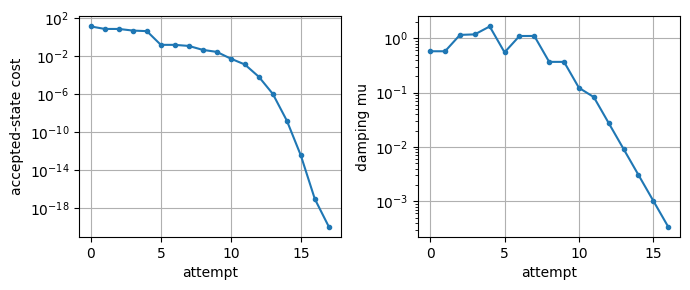

In [3]:
ours = levenberg_marquardt(rfun,jfun,[-1.2,1.],max_iter=200)
reference = least_squares(rfun,[-1.2,1.],jac=jfun,method='lm')
print('LM estimate/status:',ours.x,ours.status)
print('SciPy LM:',reference.x)
print('rejected attempts:',sum(not p['accepted'] for p in ours.history))
assert np.allclose(ours.x,reference.x,atol=1e-6)
history = ours.history[1:]
fig,ax = plt.subplots(1,2,figsize=(7,3))
ax[0].semilogy([max(p['cost'],1e-20) for p in ours.history],'.-')
ax[0].set(xlabel='attempt',ylabel='accepted-state cost')
ax[1].semilogy([p['control'] for p in history],'.-')
ax[1].set(xlabel='attempt',ylabel='damping mu')
plt.tight_layout();plt.show()

## 刹车有用，但不是自动驾驶的全部

LM 不能保证找到全局最低点，也不会自动满足参数上下界。要求速率非负时，应选支持边界的求解方式，例如第12章的 SciPy `trf`。若仪器在一段范围内拧了也没反应，雅可比为零，单纯增加阻尼也不会让信号出现。

本书如果发现阻尼很大、步子极小、梯度仍不小，会报 `stalled`，意思是“卡住了”，不是“已经成功”。图上尝试次数也不能直接拿来比较不同库的效率，它们对尝试和求值的计数未必相同。

## 动手试与解答

在第一格三种 `mu` 中加入 `10.` 和 `1000.`，比较步长和增益比。先猜它们的趋势，再看实际打印。这个小实验只比较同一位置的一步，不代表完整优化所需时间。

问题一：加大 $\mu$，真实分数就一定下降吗？

解答：不一定。它主要让局部步保守，真正是否变好仍要算原目标检查。

问题二：拒绝一步后，当前位置变了吗？

解答：没有。调整阻尼，从原位置重新提议。

问题三：预测下降为零怎么办？

解答：先别相除。检查是否已到一阶停点、方向没信息或有数值问题，再明确停止或拒绝。返回状态应把理由告诉使用者。